# 5b — Flood-Scenario Accessibility, Costa Rica

## Purpose

How much worse does access to health care get when a flood closes every exposed road in one
hydrological basin at once?

Notebook 2 answers a different question — it removes **one** physical road at a time (single point
of failure) across the whole network. This notebook removes **all** flood-exposed roads in a basin
**simultaneously**, which is the correlated-failure case that a single-point analysis cannot
represent, and measures the effect on travel time from population centres to hospitals and EBAIS.

> ### ⚠ This is not risk
>
> A scenario removes every flood-exposed road in a basin **with certainty**. There is no fragility
> curve, no closure probability, no damage model and no duration. "Population isolated by basin *X*"
> means *"population isolated **if** every road in X whose modelled RP100 depth exceeds 0.25 m were
> simultaneously impassable"*. Exposure is being used as a screen, not as an impact estimate.
> This is the same framing recorded for notebook 5a — see `MD/5a_Main_Network_Hazard_Criticality_CR_plan.md` §4.10.

## Inputs

| File | Description |
|------|-------------|
| `intermediate_results/gpkg/network/main_network_directed.gpkg` | Directed, AADT-attributed main road network from 1b (EPSG:8908, `fft` in hours) |
| `intermediate_results/gpkg/hazard_exposure/main_network_hazard_exposure.gpkg` | Per-edge hazard sampling from 4a — `flood_depth_rp10 … rp500` used here. **No raster is opened in this notebook** |
| `input_files/CENTROS_POBLACION/centros_poblados_localidades.shp` | 493 locality points, population in `INEC_PROY` (origin set A) |
| `input_files/cri_pd_2020_1km_UNadj_ASCII_XYZ.csv` | WorldPop 2020 1 km population **density** grid (origin set B) |
| `input_files/salud/hospitales_cr.shp` | 27 geocoded hospitals (sink sector 1) |
| `input_files/salud/ebais_cr.shp` | 949 EBAIS primary-care points (sink sector 2) |
| `input_files/hybas_na_lev01-12_v1c/hybas_na_lev08_v1c.shp` | HydroBASINS level 08, North/Central America (22,533 basins continent-wide; 124 intersect Costa Rica) — **the scenario unit** |

## Outputs

| File | Description |
|------|-------------|
| `intermediate_results/gpkg/travel_disruptions/flood_scenario_accessibility.gpkg` | Layers `scenarios` (basin geometry + impact per config × sector) and `origins_affected` (per-origin detail, affected origins only) |
| `intermediate_results/parquet/flood_scenarios/scenario_edges.parquet` | The `scenario_id → physical_edge_id` partition |
| `intermediate_results/parquet/flood_scenarios/scenario_summary.parquet` | Scenario × config × sector summary — 5c's input |
| `intermediate_results/parquet/flood_scenarios/rp_sensitivity.parquet` | Exposure and impact across RP10–RP500 |
| `figures/flood_scenario_*.png` | Five figures (§13) |

## Processing steps

1. Load the 1b network and the 4a hazard exposure; assert they join 1:1 on `id`
2. Build a **lean** directed igraph graph (4 edge attributes only — the scenario loop copies it)
3. Snap **both** origin sets to the network; report snap-distance diagnostics
4. Snap both sink sectors; report the EBAIS co-location diagnostic
5. Baseline OD for 2 origin sets × 2 sectors; derive the isolation penalty from the data
6. Partition flood-exposed physical roads into basins → the scenario table
7. Scenario loop: delete each basin's `physical_edge_id` groups, recompute OD (**unbuffered**)
8. Apply the 50 km buffer as a post-hoc mask → the four configurations
9. Summarise, save, plot

## Configuration matrix

Two choices that materially change the answer are run as **configurations** rather than settled in
advance. Every output row carries a `config` column.

|  | No buffer | 50 km buffer (Serbia's rule) |
|---|---|---|
| **Localities** (493) | `loc_nobuf` | `loc_buf50` |
| **WorldPop** (62,053 cells) | `wp_nobuf` | `wp_buf50` |

`loc_nobuf` is the **reporting default**: headline numbers quote it unless a caption says otherwise.

The buffer changes *which origins enter the summary* and *the denominator* — it never changes a
travel time, because each origin routes independently. So the matrix is computed as **2 OD runs,
not 4**, with the buffer applied afterwards as a mask.

## Caveats

- **Main network only.** Origins and facilities snap to the nearest main-network node, so
  first/last-mile travel is invisible. This is severe for EBAIS — see the `TODO-fix` in §4.
- **Depth statistics are edge-level maxima.** 4a reduces each raster to one scalar per edge, so
  "mean depth in scenario X" is a mean of per-edge maxima, not a mean of cell depths.
- **The 0.25 m trafficability threshold is inherited from the Serbia pipeline, not derived.**
- **Scenarios are independent.** One basin floods at a time; a regional event spanning several
  basins is never represented.
- **Two population bases coexist in this repository** (3d uses WorldPop, 2/2b use localities).
  Running both here closes the gap for 5b, but only the locality arm carries `CÓDIGO_DTA`, so a
  downstream IDS-quintile crossing can use the `loc_*` configurations only.

Plan and verified numbers: `MD/5b_Run_Flood_Scenarios_Accessibility_CR_plan.md`.

## 1 · Setup

In [1]:
import sys
import warnings
from pathlib import Path

import geopandas as gpd
import igraph as ig
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely
from tqdm.auto import tqdm

BASE_DIR = Path.cwd().parent          # notebook lives in /notebooks
sys.path.append(str(BASE_DIR))

# Shared CR map style: extent, basemap, outline, cities, legend
from src.map_style_cr import style_cr_map

data_path = BASE_DIR / "input_files"
figure_path = BASE_DIR / "figures"
intermediate_path = BASE_DIR / "intermediate_results"

# ---- Inputs ------------------------------------------------------------
network_gpkg = intermediate_path / "gpkg" / "network" / "main_network_directed.gpkg"
hazard_gpkg = (
    intermediate_path / "gpkg" / "hazard_exposure" / "main_network_hazard_exposure.gpkg"
)
population_shp = data_path / "CENTROS_POBLACION" / "centros_poblados_localidades.shp"
worldpop_csv = data_path / "cri_pd_2020_1km_UNadj_ASCII_XYZ.csv"
hospitals_shp = data_path / "salud" / "hospitales_cr.shp"
ebais_shp = data_path / "salud" / "ebais_cr.shp"
basins_shp = data_path / "hybas_na_lev01-12_v1c" / "hybas_na_lev08_v1c.shp"

# ---- Outputs -----------------------------------------------------------
scenario_gpkg = (
    intermediate_path / "gpkg" / "travel_disruptions" / "flood_scenario_accessibility.gpkg"
)
parquet_dir = intermediate_path / "parquet" / "flood_scenarios"
parquet_dir.mkdir(parents=True, exist_ok=True)
scenario_gpkg.parent.mkdir(parents=True, exist_ok=True)
figure_path.mkdir(parents=True, exist_ok=True)

# ---- Constants ---------------------------------------------------------
# These must stay consistent with notebooks 2, 2b and 5a - see CLAUDE.md.
WORKING_EPSG = 8908            # CR-SIRGAS / CRTM05, metres
FLOOD_THRESHOLD_M = 0.25       # trafficability threshold; INHERITED from Serbia's 5a, not derived
SCENARIO_RP = 100              # return period defining the scenario set
ALL_RPS = [10, 20, 50, 75, 100, 200, 500]
ISOLATION_PENALTY_FACTOR = 2.0  # multiple of max baseline OD time, as in notebook 2
BUFFER_M = 50_000              # Serbia's population buffer, run as a configuration
FAR_SNAP_WARN_M = 5_000        # origins snapping further than this are reported

# Routing attributes carried onto graph edges. Deliberately minimal: the scenario
# loop copies the graph once per basin, so attaching geometry or the full
# attribute table would be very expensive. Same list as notebook 2.
GRAPH_EDGE_ATTRS = ["id", "physical_edge_id", "road_length", "fft"]

CONFIGS = ["loc_nobuf", "loc_buf50", "wp_nobuf", "wp_buf50"]
DEFAULT_CONFIG = "loc_nobuf"
SECTORS = ["hospitals", "ebais"]

required = [network_gpkg, hazard_gpkg, population_shp, worldpop_csv, hospitals_shp, ebais_shp]
for p in required:
    if not p.exists():
        raise FileNotFoundError(
            f"Missing input: {p}\n"
            "If this path lives on OneDrive, make sure the folder is downloaded locally "
            "('Always keep on this device') - cloud placeholders cannot be opened."
        )

# The basin layer is the one input that may not be present yet. The notebook runs
# every step that does not need it and reports clearly where it stopped.
BASINS_AVAILABLE = basins_shp.exists()

print(f"Base directory : {BASE_DIR}")
print(f"Working CRS    : EPSG:{WORKING_EPSG}")
print(f"Scenario rule  : RP{SCENARIO_RP} depth > {FLOOD_THRESHOLD_M} m (inherited, not derived)")
print(f"Basins         : {'found' if BASINS_AVAILABLE else 'NOT FOUND -> ' + str(basins_shp)}")

Base directory : /Users/joeldeplaen/Library/CloudStorage/OneDrive-VrijeUniversiteitAmsterdam/Documents/GitHub/Criticality-Analysis-CR
Working CRS    : EPSG:8908
Scenario rule  : RP100 depth > 0.25 m (inherited, not derived)
Basins         : found


## 2 · Network and hazard exposure

In [2]:
base_network = gpd.read_file(network_gpkg, layer="main_network_directed")
assert base_network.crs.to_epsg() == WORKING_EPSG, f"Network CRS is {base_network.crs}"
missing = {"from_id", "to_id", "id", "physical_edge_id", "fft", "road_length"} - set(
    base_network.columns
)
assert not missing, f"Network missing required columns: {missing}"

hazard = gpd.read_file(hazard_gpkg).drop(columns="geometry")
assert set(hazard["id"]) == set(base_network["id"]), "Hazard layer does not join 1:1 on `id`"

flood_cols = [f"flood_depth_rp{rp}" for rp in ALL_RPS]
network = base_network.merge(hazard[["id"] + flood_cols], on="id", validate="1:1")

n_edges = len(network)
n_physical = network["physical_edge_id"].nunique()
total_km = network["road_length"].sum()

print(f"Directed edges   : {n_edges:,}")
print(f"Physical roads   : {n_physical:,}")
print(f"Network length   : {total_km:,.0f} km")
print("\nFlood exposure by return period (depth > "
      f"{FLOOD_THRESHOLD_M} m), from 4a - no raster is opened here:")
rows = []
for rp in ALL_RPS:
    m = network[f"flood_depth_rp{rp}"].fillna(0) > FLOOD_THRESHOLD_M
    rows.append({
        "RP": rp,
        "edges": int(m.sum()),
        "physical_roads": int(network.loc[m, "physical_edge_id"].nunique()),
        "km": round(network.loc[m, "road_length"].sum()),
        "pct_network_km": round(100 * network.loc[m, "road_length"].sum() / total_km, 1),
    })
exposure_by_rp = pd.DataFrame(rows)
print(exposure_by_rp.to_string(index=False))

Directed edges   : 9,764
Physical roads   : 5,012
Network length   : 29,528 km

Flood exposure by return period (depth > 0.25 m), from 4a - no raster is opened here:
 RP  edges  physical_roads   km  pct_network_km
 10    688             344 4536            15.4
 20    704             352 4600            15.6
 50    722             361 4654            15.8
 75    742             371 4702            15.9
100    756             378 4839            16.4
200    778             389 4948            16.8
500    796             398 5041            17.1


## 3 · Graph and node table

In [3]:
def build_graph(net, attrs=GRAPH_EDGE_ATTRS):
    """Directed igraph graph carrying only the attributes the routing needs.

    Deliberately NOT utils.accessibility_functions.create_graph_for_spatial_matching:
    that helper attaches every column (including geometry) as an edge attribute,
    which makes the per-scenario graph.copy() very expensive. Same lean approach as
    notebook 2. The utils version is left untouched for the Serbia notebooks.
    """
    edges = net[["from_id", "to_id"] + attrs]
    return ig.Graph.TupleList(
        edges.itertuples(index=False), directed=True, edge_attrs=attrs
    )


def build_node_table(net, graph):
    """One row per graph vertex: its id, its geometry, its igraph index."""
    name_to_vid = {name: i for i, name in enumerate(graph.vs["name"])}
    first = net.geometry.apply(lambda g: shapely.Point(g.coords[0]))
    last = net.geometry.apply(lambda g: shapely.Point(g.coords[-1]))
    nodes = pd.concat([
        pd.DataFrame({"node_id": net["from_id"].values, "geometry": first.values}),
        pd.DataFrame({"node_id": net["to_id"].values, "geometry": last.values}),
    ]).drop_duplicates("node_id")
    nodes["vertex_id"] = nodes["node_id"].map(name_to_vid)
    nodes = nodes.dropna(subset=["vertex_id"]).astype({"vertex_id": int})
    return gpd.GeoDataFrame(nodes, geometry="geometry", crs=net.crs).reset_index(drop=True)


graph = build_graph(network)
nodes = build_node_table(network, graph)
node_tree = shapely.STRtree(nodes.geometry.values)

# Edge indices grouped by physical road: the scenario loop deletes whole groups,
# so this lookup is built once instead of scanning graph.es per scenario.
edge_idx_by_physical = (
    pd.Series(range(graph.ecount()), index=graph.es["physical_edge_id"])
    .groupby(level=0).apply(list).to_dict()
)

components = graph.connected_components(mode="weak")
print(f"Vertices        : {graph.vcount():,}")
print(f"Edges           : {graph.ecount():,}")
print(f"Weak components : {len(components)} (giant holds {max(len(c) for c in components):,} vertices)")
print(f"Node table      : {len(nodes):,} rows")
print(f"Physical groups : {len(edge_idx_by_physical):,}")

Vertices        : 3,909
Edges           : 9,764
Weak components : 1 (giant holds 3,909 vertices)
Node table      : 3,909 rows
Physical groups : 5,012


## 4 · Origins — both sets

In [4]:
def snap_points(gdf, nodes, tree):
    """Vectorised nearest-node snap. Returns (vertex_id array, distance array).

    Vectorised rather than utils.accessibility_functions.nearest_network_nodes,
    which applies row-wise and takes minutes on the 62k-cell WorldPop grid.
    """
    idx = tree.nearest(gdf.geometry.values)
    vertex_id = nodes["vertex_id"].values[idx]
    dist = shapely.distance(gdf.geometry.values, nodes.geometry.values[idx])
    return vertex_id, dist


# --- Origin set A: CENTROS_POBLACION localities (notebooks 2 / 2b use these) ---
localities = gpd.read_file(population_shp).to_crs(WORKING_EPSG)
localities = localities[localities["INEC_PROY"].notna()].reset_index(drop=True)
localities["population"] = localities["INEC_PROY"].astype(float)
localities["origin_id"] = localities["CÓDIGO"].astype(str)
localities["vertex_id"], localities["snap_m"] = snap_points(localities, nodes, node_tree)

# --- Origin set B: WorldPop 1 km grid (notebook 3d uses this) ---
# Z is population DENSITY (people/km2); convert to people per cell with the
# latitude-dependent 30-arc-second cell area, exactly as 3d does.
wp = pd.read_csv(worldpop_csv).rename(columns={"Z": "density"})
wp = wp[wp["density"] > 0].reset_index(drop=True)
_cell_deg = 1 / 120
_area_km2 = (111.320 * np.cos(np.radians(wp["Y"])) * _cell_deg) * (110.574 * _cell_deg)
wp["population"] = wp["density"] * _area_km2
worldpop = gpd.GeoDataFrame(
    wp, geometry=gpd.points_from_xy(wp["X"], wp["Y"]), crs="EPSG:4326"
).to_crs(WORKING_EPSG)
worldpop["origin_id"] = worldpop.index.astype(str)
worldpop["vertex_id"], worldpop["snap_m"] = snap_points(worldpop, nodes, node_tree)

ORIGIN_SETS = {"loc": localities, "wp": worldpop}

rows = []
for key, df in ORIGIN_SETS.items():
    far = df["snap_m"] > FAR_SNAP_WARN_M
    rows.append({
        "origin_set": key,
        "n_origins": len(df),
        "population": round(df["population"].sum()),
        "distinct_vertices": df["vertex_id"].nunique(),
        "snap_median_m": round(df["snap_m"].median()),
        "snap_p90_m": round(df["snap_m"].quantile(0.90)),
        "snap_max_m": round(df["snap_m"].max()),
        f"beyond_{FAR_SNAP_WARN_M // 1000}km": int(far.sum()),
    })
origin_diagnostics = pd.DataFrame(rows)
print(origin_diagnostics.to_string(index=False))

print(f"\nLocalities snapping beyond {FAR_SNAP_WARN_M / 1000:.0f} km "
      "(these carry the largest last-mile error):")
_far = localities.loc[localities["snap_m"] > FAR_SNAP_WARN_M, ["NOMBRE", "population", "snap_m"]]
print(_far.sort_values("snap_m", ascending=False).to_string(index=False))

origin_set  n_origins  population  distinct_vertices  snap_median_m  snap_p90_m  snap_max_m  beyond_5km
       loc        493     5167278                485            247        1425       16873           6
        wp      62053     5137882               3297           2712        8850       40941       15117

Localities snapping beyond 5 km (these carry the largest last-mile error):
            NOMBRE  population       snap_m
    Puerto Jiménez     13765.0 16872.644962
Barra del Colorado      5025.0 12342.366247
           Nancite      1675.0  8158.460803
           Cabanga      1109.0  7304.365178
            Amubri      8853.0  5845.082926
          Delicias      5413.0  5340.043189


## 5 · Sinks — hospitals and EBAIS

In [5]:
hospitals = gpd.read_file(hospitals_shp).to_crs(WORKING_EPSG)
hospitals = hospitals[hospitals["estado"] == "OK"].drop_duplicates("place_id")
hospitals = hospitals.reset_index(drop=True)
hospitals["sink_id"] = hospitals["place_id"].astype(str)
hospitals["vertex_id"], hospitals["snap_m"] = snap_points(hospitals, nodes, node_tree)

# TODO-fix: EBAIS access times are structurally degenerate on this network.
# The 949 EBAIS collapse onto ~767 of the graph's 3,909 nodes (19.6%), so 58.8%
# of localities - 52.0% of the population - sit at exactly 0 min from their
# nearest EBAIS and NO road closure can change their access time. Measured
# 2026-09-11; see MD/5b_Run_Flood_Scenarios_Accessibility_CR_plan.md section 3.2.
#
# Cause: routing runs on the 1b main network only, so origins and facilities
# both snap to the nearest main-network node and first/last-mile travel is
# invisible. Not fixable in 5b - it needs the full road network (cantonal and
# local roads), which is 1b's scope.
#
# Origin set does not fix it: the WorldPop 1 km grid (62,053 cells) halves it
# but leaves 30.6% of population at 0 min, and worsens origin snapping from a
# 247 m median to 2,712 m. Both sets are run as configurations so the spread is
# visible rather than assumed away.
#
# Until fixed: every EBAIS statistic is reported twice - over all origins and
# over the non-co-located subset. Hospitals (27 sinks, 0.7% of nodes) are
# unaffected and carry the headline.
ebais = gpd.read_file(ebais_shp).to_crs(WORKING_EPSG).reset_index(drop=True)
ebais["sink_id"] = ebais.index.astype(str)
ebais["vertex_id"], ebais["snap_m"] = snap_points(ebais, nodes, node_tree)

SINK_SETS = {"hospitals": hospitals, "ebais": ebais}

rows = []
for name, df in SINK_SETS.items():
    vids = df["vertex_id"].unique()
    rows.append({
        "sector": name,
        "n_points": len(df),
        "distinct_vertices": len(vids),
        "pct_of_network_nodes": round(100 * len(vids) / graph.vcount(), 1),
        "snap_median_m": round(df["snap_m"].median()),
        "snap_max_m": round(df["snap_m"].max()),
    })
sink_diagnostics = pd.DataFrame(rows)
print(sink_diagnostics.to_string(index=False))
print("\n^ 'pct_of_network_nodes' is the degeneracy warning: the higher it is, the more "
      "origins\n  sit on a sink and can never be affected by a road closure.")

   sector  n_points  distinct_vertices  pct_of_network_nodes  snap_median_m  snap_max_m
hospitals        27                 27                   0.7            337        1555
    ebais       949                767                  19.6            361       27266

^ 'pct_of_network_nodes' is the degeneracy warning: the higher it is, the more origins
  sit on a sink and can never be affected by a road closure.


## 6 · Baseline access and the isolation penalty

In [6]:
def nearest_times(graph, origins, sink_df):
    """Travel time (hours) from every origin to its nearest sink.

    Routes once per DISTINCT origin vertex, then maps back to origins.
    """
    src = np.unique(origins["vertex_id"].values)
    tgt = np.unique(sink_df["vertex_id"].values)
    matrix = np.asarray(graph.distances(source=src, target=tgt, weights="fft"))
    lookup = dict(zip(src, matrix.min(axis=1)))
    return origins["vertex_id"].map(lookup).to_numpy(dtype=float)


baseline = {}
for okey, odf in ORIGIN_SETS.items():
    for sector, sdf in SINK_SETS.items():
        baseline[(okey, sector)] = nearest_times(graph, odf, sdf)

# One penalty for the whole notebook, derived from the largest baseline across all
# four arms, so that configurations stay comparable. Same rule as notebook 2:
# being cut off must always cost more than the longest legitimate journey.
max_baseline_hours = float(max(np.nanmax(v[np.isfinite(v)]) for v in baseline.values()))
ISOLATION_PENALTY_HOURS = float(np.ceil(max_baseline_hours * ISOLATION_PENALTY_FACTOR))

rows = []
for (okey, sector), tt in baseline.items():
    pop = ORIGIN_SETS[okey]["population"].to_numpy(dtype=float)
    order = np.argsort(tt)
    cum = np.cumsum(pop[order]) / pop.sum()
    rows.append({
        "origin_set": okey,
        "sector": sector,
        "n_unreachable": int(np.isinf(tt).sum()),
        "pop_wtd_median_min": round(float(tt[order][np.searchsorted(cum, 0.5)] * 60), 1),
        "pop_wtd_mean_min": round(float(np.average(tt, weights=pop) * 60), 1),
        "max_min": round(float(np.nanmax(tt[np.isfinite(tt)]) * 60), 1),
        "pop_at_zero_pct": round(100 * pop[tt == 0].sum() / pop.sum(), 1),
    })
baseline_summary = pd.DataFrame(rows)
print(baseline_summary.to_string(index=False))

print(f"\nLongest baseline trip : {max_baseline_hours:.2f} h")
print(f"Isolation penalty     : {ISOLATION_PENALTY_HOURS:.0f} h "
      f"({ISOLATION_PENALTY_FACTOR:g} x the longest baseline trip)")
print("  Derived from the data, and shared by all four configurations so they stay comparable.")
print("  Replaces the flat 12 h hard-coded in the Serbia script.")

# The non-degenerate subset, used for the second set of EBAIS statistics.
NON_DEGENERATE = {
    (okey, sector): baseline[(okey, sector)] > 0
    for okey in ORIGIN_SETS for sector in SINK_SETS
}
for (okey, sector), mask in NON_DEGENERATE.items():
    if sector == "ebais":
        pop = ORIGIN_SETS[okey]["population"].to_numpy(dtype=float)
        print(f"  EBAIS non-co-located subset [{okey}]: {mask.sum():,}/{len(mask):,} origins, "
              f"{100 * pop[mask].sum() / pop.sum():.1f}% of population")

origin_set    sector  n_unreachable  pop_wtd_median_min  pop_wtd_mean_min  max_min  pop_at_zero_pct
       loc hospitals              0                10.5              19.4    146.1              1.6
       loc     ebais              0                 0.0               1.2     41.1             52.0
        wp hospitals              0                11.6              21.6    209.1              1.8
        wp     ebais              0                 1.3               3.1     90.9             30.6

Longest baseline trip : 3.49 h
Isolation penalty     : 7 h (2 x the longest baseline trip)
  Derived from the data, and shared by all four configurations so they stay comparable.
  Replaces the flat 12 h hard-coded in the Serbia script.
  EBAIS non-co-located subset [loc]: 203/493 origins, 48.0% of population
  EBAIS non-co-located subset [wp]: 46,485/62,053 origins, 69.4% of population


## 7 · Scenario partition — flood-exposed roads by basin

A scenario is one HydroBASINS level-08 basin; all flood-exposed physical roads whose **majority
length** falls in that basin are removed together.

Level 08 rather than the Serbia pipeline's level 09, because Costa Rica is ~1.7× smaller than
Serbia and level 09 would fragment it into basins holding one or zero exposed roads. The count
printed below is the check on that choice.

Roads are assigned by **majority length**, not by Serbia's "first basin the geometry intersects",
which is arbitrary and order-dependent for any road crossing a boundary.

In [7]:
if not BASINS_AVAILABLE:
    print("=" * 78)
    print("BASIN LAYER NOT FOUND - scenario construction and everything downstream is SKIPPED.")
    print(f"Expected: {basins_shp}")
    print()
    print("To enable: download HydroBASINS level 08 for North/Central America")
    print("  https://www.hydrosheds.org/products/hydrobasins  ->  hybas_na_lev08_v1c.shp")
    print(f"  and place the shapefile (with .dbf/.shx/.prj) in {basins_shp.parent}")
    print("  (level 09 is the fallback if level 08 yields too few scenarios)")
    print()
    print("Everything above this cell ran on real data and is valid. Re-run the whole")
    print("notebook once the file is in place; no other change is needed.")
    print("=" * 78)
    scenario_edges = None
    basins = None
else:
    basins = gpd.read_file(basins_shp).to_crs(WORKING_EPSG)

    exposed_mask = network[f"flood_depth_rp{SCENARIO_RP}"].fillna(0) > FLOOD_THRESHOLD_M
    exposed = network.loc[exposed_mask]
    exposed_roads = exposed.dissolve("physical_edge_id", aggfunc={"road_length": "sum"})
    exposed_roads = exposed_roads.reset_index()

    # Clip basins to the roads' extent so the printed count is about CR, not the continent.
    basins = basins[basins.intersects(shapely.box(*network.total_bounds))].reset_index(drop=True)

    # Majority-length assignment: overlay each exposed road with the basins and keep
    # the basin holding the greatest share of that road's length.
    pieces = gpd.overlay(
        exposed_roads[["physical_edge_id", "geometry"]],
        basins[["HYBAS_ID", "geometry"]],
        how="identity",
        keep_geom_type=True,
    )
    pieces["piece_km"] = pieces.length / 1000
    winner = (
        pieces.sort_values("piece_km", ascending=False)
        .drop_duplicates("physical_edge_id")[["physical_edge_id", "HYBAS_ID"]]
    )
    n_multi = int((pieces.groupby("physical_edge_id")["HYBAS_ID"].nunique() > 1).sum())

    scenario_edges = winner.rename(columns={"HYBAS_ID": "scenario_id"}).dropna()
    scenario_edges["scenario_id"] = scenario_edges["scenario_id"].astype("int64")
    scenario_edges.to_parquet(parquet_dir / "scenario_edges.parquet", index=False)

    km_by_road = exposed_roads.set_index("physical_edge_id")["road_length"]
    scenario_table = (
        scenario_edges.assign(km=scenario_edges["physical_edge_id"].map(km_by_road))
        .groupby("scenario_id")
        .agg(n_roads=("physical_edge_id", "nunique"), km=("km", "sum"))
        .sort_values("km", ascending=False)
    )
    scenario_table["pct_network_km"] = 100 * scenario_table["km"] / total_km

    print(f"Basins intersecting CR          : {len(basins):,}")
    print(f"Basins with >=1 exposed road    : {len(scenario_table):,}  <- the scenario count")
    print(f"Exposed physical roads          : {exposed_roads['physical_edge_id'].nunique():,}")
    print(f"Exposed length                  : {exposed_roads['road_length'].sum():,.0f} km "
          f"({100 * exposed_roads['road_length'].sum() / total_km:.1f}% of network)")
    print(f"Roads spanning >1 basin         : {n_multi:,} "
          "(assigned by majority length; this is the size of the ambiguity)")
    if len(scenario_table) < 10:
        print("\n!! Fewer than 10 scenarios - level 08 is too coarse for CR. "
              "Re-run with hybas_na_lev09_v1c.shp.")
    print("\nLargest scenarios by exposed length:")
    print(scenario_table.head(10).round(1).to_string())

Basins intersecting CR          : 124
Basins with >=1 exposed road    : 65  <- the scenario count
Exposed physical roads          : 378
Exposed length                  : 4,839 km (16.4% of network)
Roads spanning >1 basin         : 87 (assigned by majority length; this is the size of the ambiguity)

Largest scenarios by exposed length:
             n_roads     km  pct_network_km
scenario_id                                
7080001090         9  232.9             0.8
7080001220        20  194.9             0.7
7080054820        27  193.8             0.7
7080883450         5  190.7             0.6
7080054660         6  177.1             0.6
7080001360        13  152.2             0.5
7080883180        11  146.2             0.5
7080054920         8  138.8             0.5
7080883290         9  134.7             0.5
7080001420        13  131.9             0.4


### 7b · Does the 50 km buffer bind?

Serbia restricts the affected population to those within 50 km of the basin. Measured over the
RP100-exposed roads individually, a 50 km buffer reaches a **median of 5.8 %** of Costa Rica's
population — the buffer is a strong filter, not a formality, because CR's population is
concentrated in the Valle Central. This cell reports the realised per-basin capture, which is the
number that actually governs the `buf50` configurations.

In [8]:
if not BASINS_AVAILABLE:
    print("Skipped - no basin layer.")
    buffer_masks = None
else:
    scenario_ids = list(scenario_table.index)
    basin_geom = basins.set_index("HYBAS_ID").geometry

    # Per scenario, per origin set: a boolean mask of origins within 50 km of the basin.
    buffer_masks = {}
    for okey, odf in ORIGIN_SETS.items():
        tree = shapely.STRtree(odf.geometry.values)
        for sid in scenario_ids:
            hit = tree.query(basin_geom.loc[sid], predicate="dwithin", distance=BUFFER_M)
            mask = np.zeros(len(odf), dtype=bool)
            mask[hit] = True
            buffer_masks[(okey, sid)] = mask

    rows = []
    for okey, odf in ORIGIN_SETS.items():
        pop = odf["population"].to_numpy(dtype=float)
        shares = np.array([
            pop[buffer_masks[(okey, sid)]].sum() / pop.sum() for sid in scenario_ids
        ])
        rows.append({
            "origin_set": okey,
            "min_pct": round(100 * shares.min(), 1),
            "p10_pct": round(100 * np.percentile(shares, 10), 1),
            "median_pct": round(100 * np.median(shares), 1),
            "p90_pct": round(100 * np.percentile(shares, 90), 1),
            "max_pct": round(100 * shares.max(), 1),
            "basins_over_90pct": int((shares > 0.9).sum()),
        })
    buffer_capture = pd.DataFrame(rows)
    print(f"Share of national population within {BUFFER_M / 1000:.0f} km of each basin:")
    print(buffer_capture.to_string(index=False))
    print("\nIf median_pct is small, the buf50 and nobuf configurations will differ a lot;")
    print("if it approaches 100, the buffer is doing nothing and the two collapse together.")

Share of national population within 50 km of each basin:
origin_set  min_pct  p10_pct  median_pct  p90_pct  max_pct  basins_over_90pct
       loc      2.7      4.0         9.8     65.1     78.3                  0
        wp      2.9      4.2        10.3     63.2     76.1                  0

If median_pct is small, the buf50 and nobuf configurations will differ a lot;
if it approaches 100, the buffer is doing nothing and the two collapse together.


## 8 · Scenario loop

For each basin: delete every `physical_edge_id` group assigned to it (**both directions** of each
physical road — a one-way deletion would leave the road passable), then recompute nearest-facility
time for both origin sets and both sectors.

Computed **unbuffered only**. The buffer is applied in §9 as a mask over these results, because an
origin's travel time does not depend on which other origins are in the frame.

In [9]:
def summarise(delta, scenario_tt, pop, penalty):
    """Population impact for one (scenario, config, sector) combination."""
    finite = np.isfinite(delta)
    isolated = scenario_tt >= penalty
    delayed = finite & (delta > 0) & ~isolated
    total_pop = pop.sum()
    return {
        "population": total_pop,
        "pop_delayed": pop[delayed].sum(),
        "pop_isolated": pop[isolated].sum(),
        "pop_affected": pop[delayed | isolated].sum(),
        "pct_affected": 100 * pop[delayed | isolated].sum() / total_pop if total_pop else np.nan,
        # NaN, not 0.0, when nobody is merely delayed: if every affected origin is
        # cut off entirely then "mean delay" is undefined, and printing 0.0 beside
        # a large pop_isolated reads as "no delay" - the opposite of what happened.
        "mean_delta_min": float(np.average(delta[delayed], weights=pop[delayed]) * 60)
        if delayed.any() and pop[delayed].sum() > 0 else np.nan,
        "max_delta_min": float(delta[delayed].max() * 60) if delayed.any() else np.nan,
        "person_hours_added": float((delta[finite & (delta > 0)] * pop[finite & (delta > 0)]).sum()),
    }


cache_summary = parquet_dir / "scenario_summary.parquet"
cache_origins = parquet_dir / "origins_affected.parquet"

if not BASINS_AVAILABLE:
    print("Skipped - no basin layer.")
    summary_df, origins_affected = None, None
elif cache_summary.exists() and cache_origins.exists():
    summary_df = pd.read_parquet(cache_summary)
    origins_affected = pd.read_parquet(cache_origins)
    print(f"Loaded cached results: {len(summary_df):,} summary rows "
          f"({cache_summary.relative_to(BASE_DIR)}). Delete to recompute.")
else:
    summary_rows, affected_rows = [], []
    km_by_road = exposed_roads.set_index("physical_edge_id")["road_length"]
    roads_by_scenario = scenario_edges.groupby("scenario_id")["physical_edge_id"].apply(list)

    for sid in tqdm(scenario_ids, desc="scenarios"):
        pids = roads_by_scenario.loc[sid]
        edge_idx = [i for pid in pids for i in edge_idx_by_physical.get(pid, [])]

        damaged = graph.copy()
        damaged.delete_edges(edge_idx)

        depths = network.loc[
            network["physical_edge_id"].isin(pids), f"flood_depth_rp{SCENARIO_RP}"
        ].dropna()
        scenario_meta = {
            "scenario_id": sid,
            "n_roads": len(pids),
            "km_removed": float(km_by_road.loc[pids].sum()),
            "pct_network_km": float(100 * km_by_road.loc[pids].sum() / total_km),
            # Edge-level MAXIMA, not cell values - 4a reduced each raster to one
            # scalar per edge. A mean of maxima, and labelled as such.
            "depth_min_m": float(depths.min()) if len(depths) else np.nan,
            "depth_mean_of_max_m": float(depths.mean()) if len(depths) else np.nan,
            "depth_max_m": float(depths.max()) if len(depths) else np.nan,
        }
        # Both buffer shares are resolved BEFORE the origin loop, so that every row
        # carries both. Setting them inside the loop would leave buffer_pop_share_wp
        # missing on the rows emitted during the 'loc' pass.
        for _k, _df in ORIGIN_SETS.items():
            _p = _df["population"].to_numpy(dtype=float)
            scenario_meta[f"buffer_pop_share_{_k}"] = float(
                _p[buffer_masks[(_k, sid)]].sum() / _p.sum()
            )

        for okey, odf in ORIGIN_SETS.items():
            pop_all = odf["population"].to_numpy(dtype=float)
            buf_mask = buffer_masks[(okey, sid)]

            for sector, sdf in SINK_SETS.items():
                new_tt = nearest_times(damaged, odf, sdf)
                new_tt = np.where(np.isinf(new_tt), ISOLATION_PENALTY_HOURS, new_tt)
                base_tt = baseline[(okey, sector)]
                delta = new_tt - base_tt

                for buffered in (False, True):
                    sel = buf_mask if buffered else np.ones(len(odf), dtype=bool)
                    config = f"{okey}_{'buf50' if buffered else 'nobuf'}"
                    stats = summarise(
                        delta[sel], new_tt[sel], pop_all[sel], ISOLATION_PENALTY_HOURS
                    )
                    summary_rows.append({
                        **scenario_meta, "config": config, "origin_set": okey,
                        "buffered": buffered, "sector": sector, **stats,
                    })

                    # Second reading for EBAIS: non-co-located origins only.
                    if sector == "ebais":
                        sel2 = sel & NON_DEGENERATE[(okey, sector)]
                        stats2 = summarise(
                            delta[sel2], new_tt[sel2], pop_all[sel2], ISOLATION_PENALTY_HOURS
                        )
                        summary_rows.append({
                            **scenario_meta, "config": config, "origin_set": okey,
                            "buffered": buffered, "sector": "ebais_noncolocated", **stats2,
                        })

                # Per-origin detail, affected origins only (storing all origins for
                # every scenario would be millions of rows of mostly zeros).
                hit = np.isfinite(delta) & (delta > 0)
                if hit.any():
                    affected_rows.append(pd.DataFrame({
                        "scenario_id": sid, "origin_set": okey, "sector": sector,
                        "origin_id": odf["origin_id"].values[hit],
                        "population": pop_all[hit],
                        "baseline_tt_h": base_tt[hit],
                        "scenario_tt_h": new_tt[hit],
                        "delta_h": delta[hit],
                        "in_buffer": buf_mask[hit],
                    }))

    summary_df = pd.DataFrame(summary_rows)
    origins_affected = (
        pd.concat(affected_rows, ignore_index=True) if affected_rows
        else pd.DataFrame(columns=["scenario_id", "origin_set", "sector", "origin_id"])
    )
    summary_df.to_parquet(cache_summary, index=False)
    origins_affected.to_parquet(cache_origins, index=False)
    print(f"Scenarios run : {len(scenario_ids):,}")
    print(f"Summary rows  : {len(summary_df):,}")
    print(f"Affected rows : {len(origins_affected):,}")

scenarios:   0%|          | 0/65 [00:00<?, ?it/s]

Scenarios run : 65
Summary rows  : 780
Affected rows : 66,035


## 9 · Results across the configuration matrix

In [10]:
if summary_df is None:
    print("Skipped - no basin layer.")
else:
    print("National totals per configuration (sum over all scenarios; hospitals sector).\n"
          "Note the denominators differ: buf50 percentages are of the buffered population,\n"
          "nobuf percentages are of the whole country.\n")
    view = (
        summary_df[summary_df["sector"] == "hospitals"]
        .groupby("config")
        .agg(scenarios=("scenario_id", "nunique"),
             pop_isolated=("pop_isolated", "sum"),
             pop_affected=("pop_affected", "sum"),
             person_hours=("person_hours_added", "sum"),
             mean_pct_affected=("pct_affected", "mean"))
        .reindex(CONFIGS)
    )
    print(view.round(1).to_string())

    print(f"\n\nWorst 10 scenarios under the reporting default ({DEFAULT_CONFIG}), hospitals:\n")
    worst = (
        summary_df[(summary_df["config"] == DEFAULT_CONFIG)
                   & (summary_df["sector"] == "hospitals")]
        .nlargest(10, "person_hours_added")
        [["scenario_id", "n_roads", "km_removed", "depth_max_m",
          "pop_affected", "pop_isolated", "mean_delta_min", "person_hours_added"]]
    )
    print(worst.round(1).to_string(index=False))

    print("\n\nSector comparison under the reporting default "
          "(ebais_noncolocated excludes origins that sit on an EBAIS):\n")
    sect = (
        summary_df[summary_df["config"] == DEFAULT_CONFIG]
        .groupby("sector")
        .agg(denominator=("population", "mean"),
             pop_affected=("pop_affected", "sum"),
             pop_isolated=("pop_isolated", "sum"),
             person_hours=("person_hours_added", "sum"),
             mean_pct_affected=("pct_affected", "mean"))
    )
    print(sect.round(1).to_string())
    print("\n  NOTE: `ebais` and `ebais_noncolocated` necessarily share the same numerators.")
    print("  An origin sitting on an EBAIS has a baseline of 0 min and cannot be affected by")
    print("  any road closure, so it can never enter pop_affected. Excluding those origins")
    print("  therefore changes only the DENOMINATOR - which is the point: the flattering")
    print("  'share unaffected' for EBAIS is an artefact of co-location, not of resilience.")

    # --- Does the buffer actually exclude anyone who was affected? ---
    # If every affected origin already lies inside the 50 km buffer, then the
    # buf50 and nobuf configurations differ ONLY in their denominator - the
    # absolute impact numbers are identical and the percentages are not
    # comparable between them. That is a result about the buffer, not a bug,
    # but it has to be stated rather than left for the reader to infer from
    # two columns that happen to match.
    print("\n\nBuffer diagnostic - are any affected origins outside the 50 km buffer?\n")
    if len(origins_affected):
        bite = (
            origins_affected.assign(outside=~origins_affected["in_buffer"])
            .groupby(["origin_set", "sector"])
            .agg(affected_rows=("outside", "size"),
                 rows_outside=("outside", "sum"),
                 pop_outside=("population", lambda s: s[~origins_affected.loc[s.index, "in_buffer"]].sum()))
        )
        print(bite.to_string())
        n_out = int((~origins_affected["in_buffer"]).sum())
        if n_out == 0:
            print("\n  -> NONE. The 50 km buffer never drops an affected origin, so buf50 and")
            print("     nobuf report identical absolute impacts and differ only in the")
            print("     denominator. Percentages are NOT comparable across the two configs.")
        else:
            print(f"\n  -> {n_out:,} affected origin-rows fall outside the buffer, i.e. the buffer")
            print("     discards real impact. The nobuf configurations are the safer default.")
    else:
        print("  No affected origins recorded.")

National totals per configuration (sum over all scenarios; hospitals sector).
Note the denominators differ: buf50 percentages are of the buffered population,
nobuf percentages are of the whole country.

           scenarios  pop_isolated  pop_affected  person_hours  mean_pct_affected
config                                                                           
loc_nobuf         65      576047.0     1449052.0     3872321.6                0.4
loc_buf50         65      565014.0     1426986.0     3810160.8                4.7
wp_nobuf          65      493188.4     1500121.1     3324240.4                0.4
wp_buf50          65      489018.4     1490501.3     3300311.3                4.4


Worst 10 scenarios under the reporting default (loc_nobuf), hospitals:

 scenario_id  n_roads  km_removed  depth_max_m  pop_affected  pop_isolated  mean_delta_min  person_hours_added
  7080054830       18        88.9          2.3      183222.0       53629.0            16.8            410827.0
  7080054

## 10 · Return-period sensitivity

Run on `loc_nobuf` only. Seven return periods × the full matrix would be 28 configurations for a
factor that moves exposure by 1.7 percentage points of network length — one arm shows the shape.

In [11]:
if not BASINS_AVAILABLE:
    print("Skipped - no basin layer.")
    rp_sensitivity = None
else:
    odf = ORIGIN_SETS["loc"]
    pop_all = odf["population"].to_numpy(dtype=float)
    rows = []
    for rp in tqdm(ALL_RPS, desc="return periods"):
        m = network[f"flood_depth_rp{rp}"].fillna(0) > FLOOD_THRESHOLD_M
        pids = network.loc[m, "physical_edge_id"].unique()
        # Whole-country failure at this RP: an upper bound, not a basin scenario.
        edge_idx = [i for pid in pids for i in edge_idx_by_physical.get(pid, [])]
        damaged = graph.copy()
        damaged.delete_edges(edge_idx)
        new_tt = nearest_times(damaged, odf, SINK_SETS["hospitals"])
        new_tt = np.where(np.isinf(new_tt), ISOLATION_PENALTY_HOURS, new_tt)
        delta = new_tt - baseline[("loc", "hospitals")]
        stats = summarise(delta, new_tt, pop_all, ISOLATION_PENALTY_HOURS)
        rows.append({
            "RP": rp,
            "exposed_roads": len(pids),
            "km": float(network.loc[m, "road_length"].sum()),
            "pct_network_km": float(100 * network.loc[m, "road_length"].sum() / total_km),
            **stats,
        })
    rp_sensitivity = pd.DataFrame(rows)
    rp_sensitivity.to_parquet(parquet_dir / "rp_sensitivity.parquet", index=False)
    print("All flood-exposed roads in the country removed at once, per return period.")
    print("This is an upper bound on any single-basin scenario, not a scenario itself.\n")
    print(rp_sensitivity.round(1).to_string(index=False))

return periods:   0%|          | 0/7 [00:00<?, ?it/s]

All flood-exposed roads in the country removed at once, per return period.
This is an upper bound on any single-basin scenario, not a scenario itself.

 RP  exposed_roads     km  pct_network_km  population  pop_delayed  pop_isolated  pop_affected  pct_affected  mean_delta_min  max_delta_min  person_hours_added
 10            344 4536.0            15.4   5167278.0     443231.0      370033.0      813264.0          15.7            23.0           88.5           2506908.1
 20            352 4600.4            15.6   5167278.0     422776.0      390488.0      813264.0          15.7            23.8           88.5           2632526.6
 50            361 4654.1            15.8   5167278.0     400945.0      416522.0      817467.0          15.8            24.1           88.5           2797826.9
 75            371 4702.5            15.9   5167278.0     400945.0      470151.0      871096.0          16.9            24.1           88.5           3172672.7
100            378 4839.1            16.4   5167

## 11 · Save

In [12]:
if summary_df is None:
    print("Skipped - no basin layer.")
else:
    # Provenance stamped on every row so no consumer has to infer the regime.
    stamped = summary_df.assign(
        scenario_rp=SCENARIO_RP,
        flood_threshold_m=FLOOD_THRESHOLD_M,
        isolation_penalty_h=ISOLATION_PENALTY_HOURS,
        buffer_m=BUFFER_M,
        scenario_unit="hybas_na_lev08",
    )
    scenario_geom = basins.set_index("HYBAS_ID").loc[scenario_ids, ["geometry"]].reset_index()
    scenario_geom = scenario_geom.rename(columns={"HYBAS_ID": "scenario_id"})
    scenarios_gdf = gpd.GeoDataFrame(
        stamped.merge(scenario_geom, on="scenario_id", how="left"),
        geometry="geometry", crs=f"EPSG:{WORKING_EPSG}",
    )

    scenarios_gdf.to_file(scenario_gpkg, layer="scenarios", driver="GPKG")
    origins_affected.to_parquet(parquet_dir / "origins_affected.parquet", index=False)
    stamped.to_parquet(parquet_dir / "scenario_summary.parquet", index=False)

    print(f"Wrote {scenario_gpkg.relative_to(BASE_DIR)}")
    print(f"  layer 'scenarios'   : {len(scenarios_gdf):,} rows "
          f"({scenarios_gdf['scenario_id'].nunique()} scenarios x {len(CONFIGS)} configs x sectors)")
    print(f"Wrote {parquet_dir.relative_to(BASE_DIR)}/scenario_summary.parquet")
    print(f"Wrote {parquet_dir.relative_to(BASE_DIR)}/origins_affected.parquet "
          f"({len(origins_affected):,} rows)")
    print(f"Wrote {parquet_dir.relative_to(BASE_DIR)}/scenario_edges.parquet")
    print(f"Wrote {parquet_dir.relative_to(BASE_DIR)}/rp_sensitivity.parquet")

Wrote intermediate_results/gpkg/travel_disruptions/flood_scenario_accessibility.gpkg
  layer 'scenarios'   : 780 rows (65 scenarios x 4 configs x sectors)
Wrote intermediate_results/parquet/flood_scenarios/scenario_summary.parquet
Wrote intermediate_results/parquet/flood_scenarios/origins_affected.parquet (66,035 rows)
Wrote intermediate_results/parquet/flood_scenarios/scenario_edges.parquet
Wrote intermediate_results/parquet/flood_scenarios/rp_sensitivity.parquet


## 12 · Figures

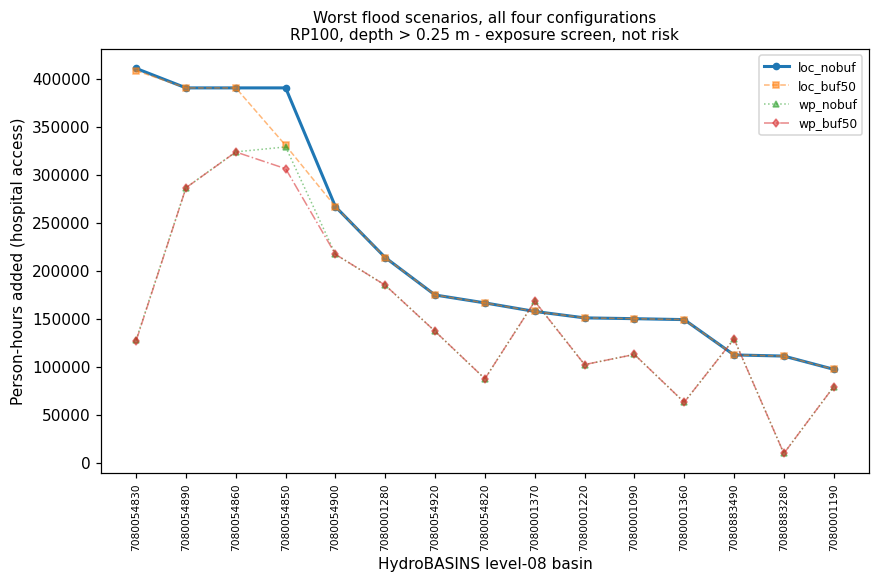

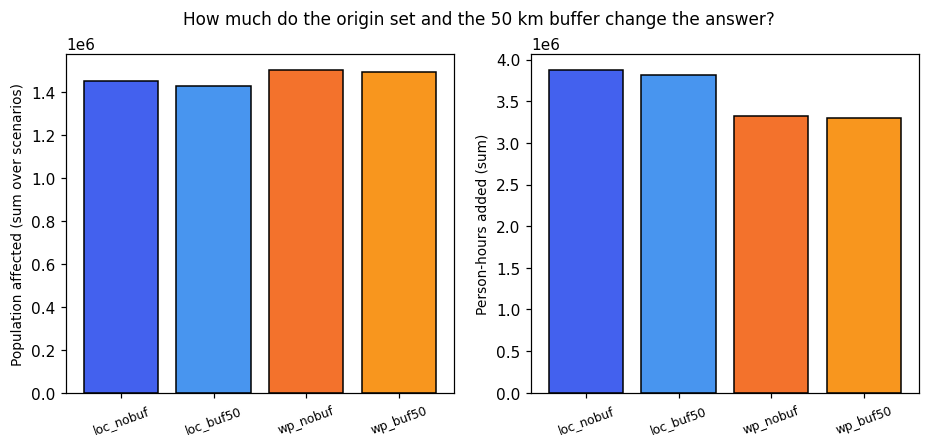

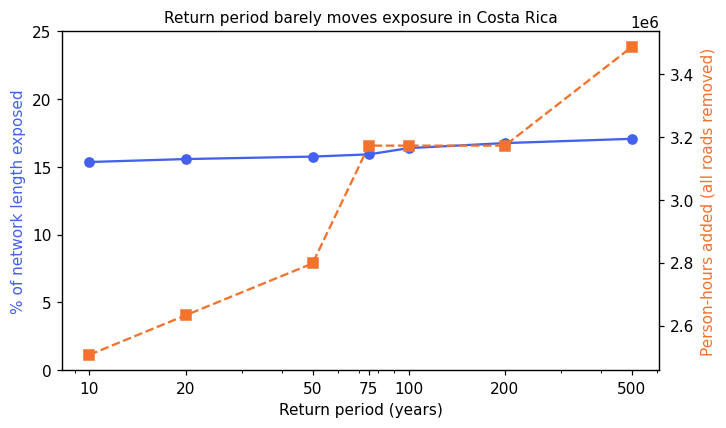

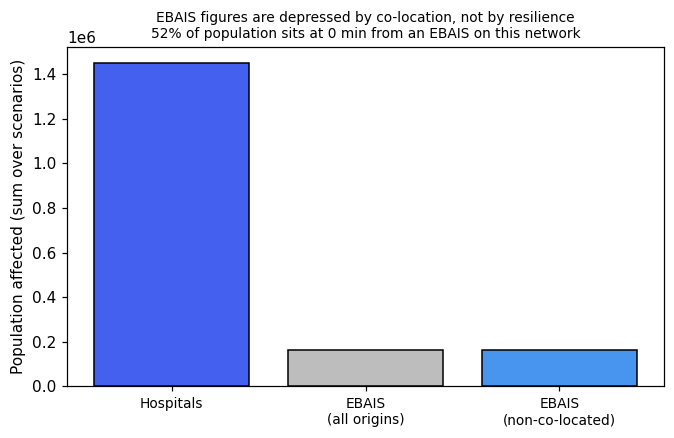

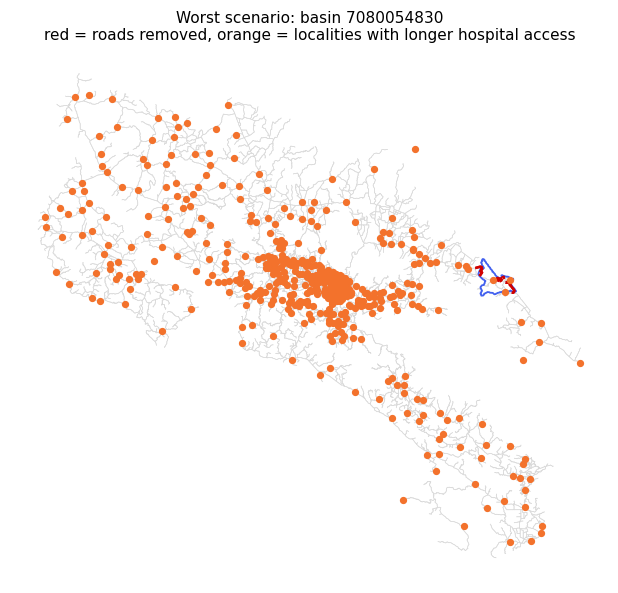

In [13]:
if summary_df is None:
    print("Skipped - no basin layer; no figures produced.")
else:
    plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight"})

    # --- 1. worst basins, default config, with the other configs overlaid ---
    fig, ax = plt.subplots(figsize=(9, 5))
    top = (summary_df[(summary_df["config"] == DEFAULT_CONFIG)
                      & (summary_df["sector"] == "hospitals")]
           .nlargest(15, "person_hours_added"))
    order = top["scenario_id"].tolist()
    x = np.arange(len(order))
    for cfg, style in zip(CONFIGS, ["-o", "--s", ":^", "-.d"]):
        s = summary_df[(summary_df["config"] == cfg) & (summary_df["sector"] == "hospitals")]
        s = s.set_index("scenario_id").reindex(order)
        ax.plot(x, s["person_hours_added"], style, label=cfg,
                lw=2.0 if cfg == DEFAULT_CONFIG else 1.0,
                alpha=1.0 if cfg == DEFAULT_CONFIG else 0.55, ms=4)
    ax.set_xticks(x)
    ax.set_xticklabels([str(s) for s in order], rotation=90, fontsize=7)
    ax.set_xlabel("HydroBASINS level-08 basin")
    ax.set_ylabel("Person-hours added (hospital access)")
    ax.set_title("Worst flood scenarios, all four configurations\n"
                 f"RP{SCENARIO_RP}, depth > {FLOOD_THRESHOLD_M} m - exposure screen, not risk",
                 fontsize=10)
    ax.legend(fontsize=8)
    fig.savefig(figure_path / "flood_scenario_worst_basins.png")
    plt.show()

    # --- 2. configuration spread ---
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, metric, label in zip(
        axes, ["pop_affected", "person_hours_added"],
        ["Population affected (sum over scenarios)", "Person-hours added (sum)"],
    ):
        agg = (summary_df[summary_df["sector"] == "hospitals"]
               .groupby("config")[metric].sum().reindex(CONFIGS))
        ax.bar(range(len(agg)), agg.values,
               color=["#4361ee", "#4895ef", "#f3722c", "#f8961e"], edgecolor="black")
        ax.set_xticks(range(len(agg)))
        ax.set_xticklabels(agg.index, rotation=20, fontsize=8)
        ax.set_ylabel(label, fontsize=9)
    fig.suptitle("How much do the origin set and the 50 km buffer change the answer?", fontsize=11)
    fig.savefig(figure_path / "flood_scenario_config_spread.png")
    plt.show()

    # --- 3. RP sensitivity ---
    if rp_sensitivity is not None:
        fig, ax1 = plt.subplots(figsize=(7, 4))
        ax1.plot(rp_sensitivity["RP"], rp_sensitivity["pct_network_km"], "-o", color="#4361ee")
        ax1.set_xscale("log")
        ax1.set_xticks(ALL_RPS)
        ax1.set_xticklabels(ALL_RPS)
        ax1.set_xlabel("Return period (years)")
        ax1.set_ylabel("% of network length exposed", color="#4361ee")
        ax1.set_ylim(0, max(25, rp_sensitivity["pct_network_km"].max() * 1.3))
        ax2 = ax1.twinx()
        ax2.plot(rp_sensitivity["RP"], rp_sensitivity["person_hours_added"], "--s", color="#f3722c")
        ax2.set_ylabel("Person-hours added (all roads removed)", color="#f3722c")
        ax1.set_title("Return period barely moves exposure in Costa Rica", fontsize=10)
        fig.savefig(figure_path / "flood_scenario_rp_sensitivity.png")
        plt.show()

    # --- 4. hospitals vs EBAIS ---
    fig, ax = plt.subplots(figsize=(7, 4))
    sect = (summary_df[summary_df["config"] == DEFAULT_CONFIG]
            .groupby("sector")["pop_affected"].sum()
            .reindex(["hospitals", "ebais", "ebais_noncolocated"]))
    ax.bar(range(len(sect)), sect.values,
           color=["#4361ee", "#bdbdbd", "#4895ef"], edgecolor="black")
    ax.set_xticks(range(len(sect)))
    ax.set_xticklabels(["Hospitals", "EBAIS\n(all origins)", "EBAIS\n(non-co-located)"], fontsize=9)
    ax.set_ylabel("Population affected (sum over scenarios)")
    ax.set_title("EBAIS figures are depressed by co-location, not by resilience\n"
                 "52% of population sits at 0 min from an EBAIS on this network", fontsize=9)
    fig.savefig(figure_path / "flood_scenario_hospital_vs_ebais.png")
    plt.show()

    # --- 5. map of the worst scenario ---
    worst_id = order[0]
    worst_pids = scenario_edges.loc[scenario_edges["scenario_id"] == worst_id, "physical_edge_id"]
    fig, ax = plt.subplots(figsize=(7, 7))
    network.plot(ax=ax, color="#d9d9d9", lw=0.4)
    basins[basins["HYBAS_ID"] == worst_id].boundary.plot(ax=ax, color="#4361ee", lw=1.2)
    network[network["physical_edge_id"].isin(worst_pids)].plot(ax=ax, color="#d00000", lw=1.6)
    hit = origins_affected[(origins_affected["scenario_id"] == worst_id)
                           & (origins_affected["origin_set"] == "loc")
                           & (origins_affected["sector"] == "hospitals")]
    if len(hit):
        pts = localities[localities["origin_id"].isin(hit["origin_id"])]
        pts.plot(ax=ax, color="#f3722c", markersize=14, zorder=5)
    from matplotlib.lines import Line2D
    style_cr_map(
        ax, WORKING_EPSG,
        legend_handles=[
            Line2D([0], [0], color="#d9d9d9", lw=2, label="Road network"),
            Line2D([0], [0], color="#4361ee", lw=1.5, label="Basin boundary"),
            Line2D([0], [0], color="#d00000", lw=2, label="Roads removed"),
            Line2D([0], [0], marker="o", linestyle="None", color="#f3722c",
                   label="Localities with longer\nhospital access"),
        ],
        legend_title=f"Basin {worst_id}",
        legend_kw=dict(fontsize=8, title_fontsize=9),
    )
    ax.set_title(f"Worst scenario: basin {worst_id}", fontsize=10)
    fig.savefig(figure_path / "flood_scenario_access_delta_map.png")
    plt.show()

## 13 · Reconciliation

In [14]:
print("=" * 70)
print("RUN RECONCILIATION")
print("=" * 70)
print(f"Network edges                 : {n_edges:,}")
print(f"Physical roads                : {n_physical:,}")
print(f"Origins - localities          : {len(localities):,} ({localities['population'].sum():,.0f} people)")
print(f"Origins - WorldPop cells      : {len(worldpop):,} ({worldpop['population'].sum():,.0f} people)")
print(f"Sinks - hospitals / EBAIS     : {len(hospitals):,} / {len(ebais):,}")
print(f"Isolation penalty             : {ISOLATION_PENALTY_HOURS:.0f} h")
print(f"Flood rule                    : RP{SCENARIO_RP}, depth > {FLOOD_THRESHOLD_M} m (inherited)")

if summary_df is None:
    print("\nSTATUS: INCOMPLETE - the basin layer is missing, so sections 7-12 were skipped.")
    print(f"        Place hybas_na_lev08_v1c.shp in {basins_shp.parent} and re-run.")
    print("        Sections 1-6 above ran on real data and their numbers are valid.")
else:
    n_expected = len(scenario_ids) * len(CONFIGS) * (len(SECTORS) + 1)
    print(f"\nScenarios                     : {len(scenario_ids):,}")
    print(f"Summary rows                  : {len(summary_df):,} (expected {n_expected:,})")
    assert len(summary_df) == n_expected, "Summary row count does not reconcile"
    print(f"Roads partitioned             : {scenario_edges['physical_edge_id'].nunique():,} "
          f"of {exposed_roads['physical_edge_id'].nunique():,} exposed")
    print("\nSTATUS: COMPLETE")

RUN RECONCILIATION
Network edges                 : 9,764
Physical roads                : 5,012
Origins - localities          : 493 (5,167,278 people)
Origins - WorldPop cells      : 62,053 (5,137,882 people)
Sinks - hospitals / EBAIS     : 27 / 949
Isolation penalty             : 7 h
Flood rule                    : RP100, depth > 0.25 m (inherited)

Scenarios                     : 65
Summary rows                  : 780 (expected 780)
Roads partitioned             : 378 of 378 exposed

STATUS: COMPLETE
